<a href="https://colab.research.google.com/github/liqq1024/GenAI_LLMs_2026Fall/blob/main/colab-notebooks/Week7_Midterm_Review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 — Midterm Review Coding Notebook

**Course:** Generative AI and Large Language Models  
**Purpose:** Optional, ungraded, self-paced practice before the midterm.

This notebook reviews the Week 1–6 path from raw text to generated output: tokenization, embeddings, attention, causal masking, prompting, and decoding. The examples are practice exercises and do not reproduce the examination questions.

**Exam reminder:** The midterm is closed book. One single-sided letter-size reference sheet is permitted. Do not use this notebook during the exam.

## How to use this notebook

Run the setup cell, predict outputs before executing each practice cell, change the examples, and use the tagged **Instructor solution** cells only after attempting the work yourself. Finish with self-assessment and the instructor preparation checklist.

The notebook uses NumPy and Matplotlib. Section 1 optionally loads two Hugging Face tokenizers; if model files are unavailable, a simple fallback tokenizer keeps the practice runnable.

In [3]:
import json
import math
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)

try:
    from transformers import AutoTokenizer
    bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
    gpt2_tokenizer = AutoTokenizer.from_pretrained("gpt2")
    print("Hugging Face tokenizers loaded.")
except Exception:
    bert_tokenizer = gpt2_tokenizer = None
    print("Hugging Face tokenizers unavailable; using a transparent fallback.")

def fallback_tokens(text):
    return text.replace(".", " .").replace(",", " ,").split()

def tokens_for(tokenizer, text):
    return fallback_tokens(text) if tokenizer is None else tokenizer.tokenize(text)

def ids_for(tokenizer, text):
    if tokenizer is None:
        return list(range(len(fallback_tokens(text))))
    return tokenizer.encode(text, add_special_tokens=False)

Hugging Face tokenizers loaded.


## Section 1 — Tokenization review

Compare token counts, subword splits, token IDs, and decoding. A longer sequence can require more computation and consume more context-window capacity, while subword pieces can represent unfamiliar words.

In [4]:
text = "Retrieval-augmented systems improve factual grounding."
for name, tokenizer in [("BERT-style", bert_tokenizer), ("GPT-style", gpt2_tokenizer)]:
    print(name)
    print("tokens:", tokens_for(tokenizer, text))
    print("count:", len(tokens_for(tokenizer, text)))
    ids = ids_for(tokenizer, text)
    print("IDs:", ids)
    if tokenizer is not None:
        print("decoded:", tokenizer.decode(ids))
    print()

print("Practice: change text to include a hyphen, a technical term, or an unfamiliar name.")

BERT-style
tokens: ['retrieval', '-', 'augmented', 'systems', 'improve', 'factual', 'ground', '##ing', '.']
count: 9
IDs: [26384, 1011, 19335, 3001, 5335, 25854, 2598, 2075, 1012]
decoded: retrieval - augmented systems improve factual grounding.

GPT-style
tokens: ['Ret', 'ri', 'eval', '-', 'au', 'gment', 'ed', 'Ġsystems', 'Ġimprove', 'Ġfactual', 'Ġgrounding', '.']
count: 12
IDs: [9781, 380, 18206, 12, 559, 5154, 276, 3341, 2987, 27234, 48459, 13]
decoded: Retrieval-augmented systems improve factual grounding.

Practice: change text to include a hyphen, a technical term, or an unfamiliar name.


### Instructor solution — Section 1

There is no single correct count because tokenization depends on the tokenizer and exact text. A strong explanation connects more tokens with more processing/context usage and explains why subword units help represent rare or unseen words. Token IDs are categorical indices; their numeric magnitude is not semantic distance.

## Section 2 — Embedding review

Token IDs become useful representations after lookup in an embedding table. Use cosine similarity to compare directions in a toy vector space.

In [5]:
def cosine_similarity(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

embeddings = {
    "retrieval": np.array([0.90, 0.30, 0.10]),
    "search": np.array([0.82, 0.35, 0.12]),
    "database": np.array([0.75, 0.42, 0.18]),
    "banana": np.array([-0.10, 0.05, 0.95]),
}
names = list(embeddings)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        print(names[i], "vs", names[j], "=", round(
            cosine_similarity(embeddings[names[i]], embeddings[names[j]]), 3
        ))

print("Practice: explain why similar directions can be useful but do not guarantee factual similarity.")

retrieval vs search = 0.996
retrieval vs database = 0.978
retrieval vs banana = 0.022
search vs database = 0.992
search vs banana = 0.058
database vs banana = 0.139
Practice: explain why similar directions can be useful but do not guarantee factual similarity.


### Instructor solution — Section 2

The retrieval/search pair should be closest in this toy example. Cosine similarity compares vector direction. Real embeddings are learned from data, so proximity is a useful signal but not a proof of truth, causality, or identical meaning.

## Section 3 — Attention review

Scaled dot-product attention is:

`softmax(QK^T / sqrt(d_k)) V`

Compute scores, scale them, normalize them, and combine the value vectors.

QK^T = [[1.  0.  0.7]]
scaled = [[0.707 0.    0.495]]
weights = [[0.434 0.214 0.351]]
context = [[1.22  0.994]]


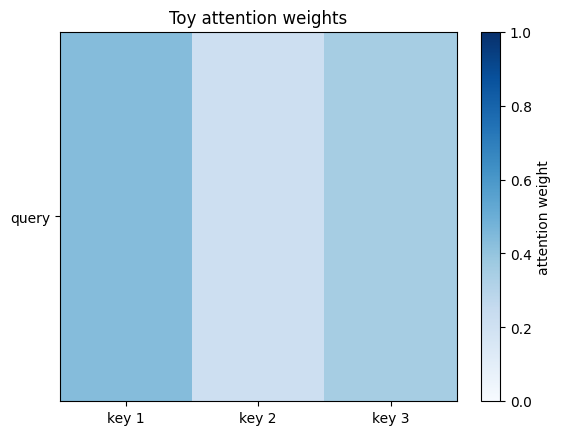

In [6]:
def softmax(x, axis=-1):
    x = np.asarray(x, dtype=float)
    z = x - np.max(x, axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

Q = np.array([[1.0, 0.0]])
K = np.array([[1.0, 0.0], [0.0, 1.0], [0.7, 0.7]])
V = np.array([[2.0, 0.0], [0.0, 3.0], [1.0, 1.0]])
scores = Q @ K.T
scaled = scores / math.sqrt(K.shape[1])
weights = softmax(scaled)
context = weights @ V
print("QK^T =", scores)
print("scaled =", np.round(scaled, 3))
print("weights =", np.round(weights, 3))
print("context =", np.round(context, 3))

plt.imshow(weights, cmap="Blues", aspect="auto", vmin=0, vmax=1)
plt.colorbar(label="attention weight")
plt.xticks(range(3), ["key 1", "key 2", "key 3"])
plt.yticks([0], ["query"])
plt.title("Toy attention weights")
plt.show()

### Instructor solution — Section 3

The first key receives the greatest score because `[1, 0]` has the largest dot product with the query. Scaling moderates score magnitude, softmax creates non-negative weights that sum to one, and the output is a weighted combination of value vectors.

## Section 4 — Causal masking

In a decoder-only model, a position may attend to itself and earlier positions, but not future positions. This preserves the next-token prediction objective.

Raw scores:
 [[ 1.69 -0.47  0.03  0.41 -0.79]
 [ 0.   -0.   -1.75  1.02  0.6 ]
 [-0.63 -0.17  0.51 -0.26 -0.24]
 [-1.45  0.55  0.12  0.27 -1.53]
 [ 1.65  0.15 -0.39  2.03 -0.05]]
Causal mask (True = blocked):
 [[False  True  True  True  True]
 [False False  True  True  True]
 [False False False  True  True]
 [False False False False  True]
 [False False False False False]]
Masked weights:
 [[1.    0.    0.    0.    0.   ]
 [0.5   0.5   0.    0.    0.   ]
 [0.175 0.277 0.548 0.    0.   ]
 [0.053 0.393 0.256 0.297 0.   ]
 [0.334 0.074 0.043 0.488 0.061]]


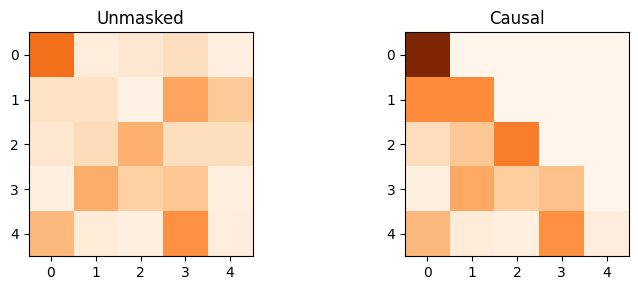

In [7]:
n = 5
raw_scores = np.round(np.random.randn(n, n), 2)
future_positions = np.triu(np.ones((n, n), dtype=bool), k=1)
masked_scores = np.where(future_positions, -1e9, raw_scores)
unmasked = softmax(raw_scores)
masked = softmax(masked_scores)
print("Raw scores:\n", raw_scores)
print("Causal mask (True = blocked):\n", future_positions)
print("Masked weights:\n", np.round(masked, 3))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(unmasked, cmap="Oranges", vmin=0, vmax=1)
axes[0].set_title("Unmasked")
axes[1].imshow(masked, cmap="Oranges", vmin=0, vmax=1)
axes[1].set_title("Causal")
plt.tight_layout()
plt.show()

### Instructor solution — Section 4

The upper-triangular future positions are assigned a very negative score, so softmax gives them approximately zero weight. Without the mask, training tokens could see future answers.

## Section 5 — Prompt engineering and structured output

A strong prompt specifies audience, task, context, constraints, and output format. Practice improving an underspecified request and checking required JSON fields.

In [8]:
original = "Explain embeddings."
improved = (
    "You are a teaching assistant for senior undergraduates. "
    "Explain word and sentence embeddings for students who know tokenization. "
    "Define an embedding, show one cosine-similarity example, name one limitation, "
    "use Markdown headings, and stay under 220 words."
)
print("Original:", original)
print("Improved:", improved)

required = ["definition", "similarity_example", "limitation"]
example = {
    "definition": "A learned vector representation.",
    "similarity_example": "Cosine similarity compares vector direction.",
    "limitation": "Proximity does not guarantee truth.",
}
print(json.dumps(example, indent=2))
print("Missing fields:", [k for k in required if k not in example])

Original: Explain embeddings.
Improved: You are a teaching assistant for senior undergraduates. Explain word and sentence embeddings for students who know tokenization. Define an embedding, show one cosine-similarity example, name one limitation, use Markdown headings, and stay under 220 words.
{
  "definition": "A learned vector representation.",
  "similarity_example": "Cosine similarity compares vector direction.",
  "limitation": "Proximity does not guarantee truth."
}
Missing fields: []


### Instructor solution — Section 5

The improved prompt identifies the audience, gives context, states the task, adds content and length constraints, and specifies a format. A required schema makes a response easier to validate, but valid JSON alone does not guarantee correctness.

## Section 6 — Generation strategies

Greedy decoding selects the highest-probability token. Top-k keeps a fixed number of candidates. Top-p keeps the smallest cumulative-probability nucleus. Lower temperature sharpens a distribution; higher temperature flattens it.

In [9]:
tokens = np.array(["answer", "summary", "example", "detail", "banana", "bicycle"])
probs = np.array([0.36, 0.27, 0.16, 0.11, 0.06, 0.04])

def temp_probs(p, temperature):
    return softmax(np.log(p) / temperature)

def top_k(tokens, probs, k):
    idx = np.argsort(probs)[::-1][:k]
    return list(zip(tokens[idx], probs[idx]))

def top_p(tokens, probs, p):
    idx = np.argsort(probs)[::-1]
    cumulative = np.cumsum(probs[idx])
    count = np.searchsorted(cumulative, p, side="left") + 1
    return list(zip(tokens[idx[:count]], probs[idx[:count]]))

print("Greedy:", tokens[np.argmax(probs)])
print("Top-k (k=3):", top_k(tokens, probs, 3))
print("Top-p (p=0.75):", top_p(tokens, probs, 0.75))
for t in [0.5, 1.0, 1.8]:
    print("temperature", t, np.round(temp_probs(probs, t), 3))

Greedy: answer
Top-k (k=3): [(np.str_('answer'), np.float64(0.36)), (np.str_('summary'), np.float64(0.27)), (np.str_('example'), np.float64(0.16))]
Top-p (p=0.75): [(np.str_('answer'), np.float64(0.36)), (np.str_('summary'), np.float64(0.27)), (np.str_('example'), np.float64(0.16))]
temperature 0.5 [0.528 0.297 0.104 0.049 0.015 0.007]
temperature 1.0 [0.36 0.27 0.16 0.11 0.06 0.04]
temperature 1.8 [0.272 0.232 0.174 0.141 0.101 0.08 ]


### Instructor solution — Section 6

Use low temperature or a narrow candidate set for consistency-sensitive tasks; use moderate diversity for creative writing or brainstorming. Decoding changes selection behavior, but it cannot supply missing knowledge or guarantee factuality.

## Section 7 — Self-assessment

Rate each topic from 1 (not confident) to 5 (can explain and apply it without notes). Replace the sample ratings with your own and generate a personal review list.

In [10]:
confidence = {
    "Generative AI concepts": 3,
    "Tokenization": 3,
    "Embeddings": 2,
    "Attention and QKV": 2,
    "Transformer decoder architecture": 3,
    "GPT training stages": 4,
    "Prompt engineering": 4,
    "Decoding strategies": 2,
    "Integrated application analysis": 2,
}
assert all(1 <= score <= 5 for score in confidence.values())
print("Personal review list:")
for topic, score in confidence.items():
    if score <= 3:
        print("-", topic)

Personal review list:
- Generative AI concepts
- Tokenization
- Embeddings
- Attention and QKV
- Transformer decoder architecture
- Decoding strategies
- Integrated application analysis


## Final review prompt

In a few sentences, explain the complete path from raw text to generated LLM output. Mention tokenization, embeddings, attention, Transformer/GPT architecture, prompting, and decoding. Then identify one pipeline decision that could affect reliability.